# Vision Assist V1


In [1]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [6]:

# ============================================================
# VISION ASSIST V1 — COMPLETE KAGGLE TRAINING SCRIPT
# Dataset: ROD Obstacle Detection
# Framework: YOLOv8 Nano + PyTorch + CUDA
# First run: 1-epoch smoke test
# ============================================================

import os
import sys
import subprocess
import importlib.util
from pathlib import Path

print("=" * 65)
print("VISION ASSIST V1 — SETUP AND TRAINING")
print("=" * 65)

# ------------------------------------------------------------
# 1. CHECK GPU
# ------------------------------------------------------------
import torch

print("\n[1/7] Checking GPU...")

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. In Kaggle, enable Settings > Accelerator > GPU, "
        "then rerun this cell."
    )

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

DEVICE = 0  # Use one Tesla T4 for this initial test.

# ------------------------------------------------------------
# 2. INSTALL YOLO IF NEEDED
# ------------------------------------------------------------
print("\n[2/7] Checking Ultralytics...")

if importlib.util.find_spec("ultralytics") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "ultralytics"
    ])

from ultralytics import YOLO
import yaml

print("Ultralytics imported successfully.")

# ------------------------------------------------------------
# 3. FIND SOURCE DATASET
# ------------------------------------------------------------
print("\n[3/7] Locating ROD dataset...")

SOURCE = Path(
    "/kaggle/input/datasets/abtinzandi/"
    "obstacle-detection-dataset/ROD-Dataset/dataset"
)

if not SOURCE.exists():
    raise FileNotFoundError(
        f"Dataset not found at {SOURCE}\n"
        "Check the Kaggle Input panel and attach the ROD dataset."
    )

DEST = Path("/kaggle/working/rod_detection")
YAML_PATH = Path("/kaggle/working/rod_detection.yaml")
OUTPUT_DIR = Path("/kaggle/working/vision_assist")

# Keep the source dataset untouched.
# Recreate only our prepared working dataset.
if DEST.exists():
    shutil.rmtree(DEST)

DEST.mkdir(parents=True, exist_ok=True)

# Preserve the source dataset's 25 class IDs and order.
CLASS_NAMES = [
    "Bike",
    "Building",
    "Car",
    "Person",
    "Stairs",
    "Traffic sign",
    "Electrical Pole",
    "Road",
    "Motorcycle",
    "Dustbin",
    "Dog",
    "Manhole",
    "Tree",
    "Guard rail",
    "Pedestrian crosswalk",
    "Truck",
    "Bus",
    "Bench",
    "Traffic Cone",
    "Fire hydrant",
    "Teraffic Barrel",
    "Plant Pot",
    "Electrical Box",
    "Chair",
    "Bicycle Rack",
]

# ------------------------------------------------------------
# 4. PREPARE DATASET AND CONVERT POLYGONS TO BOXES
# ------------------------------------------------------------
print("\n[4/7] Preparing images and annotations...")
print("Images will be linked, not copied.")

# Source folder -> YOLO split folder
SPLITS = {
    "train": "train",
    "valid": "valid",
    "test": "test",
}

summary = {}
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for source_split, output_split in SPLITS.items():
    src_images = SOURCE / source_split / "images"
    src_labels = SOURCE / source_split / "labels"

    if not src_images.is_dir() or not src_labels.is_dir():
        raise FileNotFoundError(
            f"Missing images or labels in {source_split}:\n"
            f"{src_images}\n{src_labels}"
        )

    out_images = DEST / output_split / "images"
    out_labels = DEST / output_split / "labels"
    out_images.mkdir(parents=True, exist_ok=True)
    out_labels.mkdir(parents=True, exist_ok=True)

    image_files = [
        p for p in src_images.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    if not image_files:
        raise RuntimeError(f"No images found in {src_images}")

    # Symlink images to avoid duplicating many gigabytes of data.
    for img in image_files:
        (out_images / img.name).symlink_to(img)

    bbox_count = 0
    polygon_count = 0
    skipped_count = 0
    label_files = list(src_labels.glob("*.txt"))

    for label_file in label_files:
        converted_lines = []

        for line in label_file.read_text().splitlines():
            parts = line.split()

            if not parts:
                continue

            try:
                cls = int(parts[0])
                coords = [float(v) for v in parts[1:]]
            except (ValueError, OverflowError):
                skipped_count += 1
                continue

            if not 0 <= cls < len(CLASS_NAMES):
                skipped_count += 1
                continue

            # Standard YOLO bounding box:
            # class x_center y_center width height
            if len(coords) == 4:
                x, y, w, h = coords
                annotation_type = "bbox"

            # Polygon annotation:
            # class x1 y1 x2 y2 x3 y3 ...
            elif len(coords) >= 6 and len(coords) % 2 == 0:
                xs = coords[0::2]
                ys = coords[1::2]

                xmin, xmax = min(xs), max(xs)
                ymin, ymax = min(ys), max(ys)

                x = (xmin + xmax) / 2.0
                y = (ymin + ymax) / 2.0
                w = xmax - xmin
                h = ymax - ymin
                annotation_type = "polygon"

            else:
                skipped_count += 1
                continue

            # Coordinates must be normalized to [0, 1].
            if (
                not all(0.0 <= v <= 1.0 for v in (x, y, w, h))
                or w <= 0.0
                or h <= 0.0
            ):
                skipped_count += 1
                continue

            converted_lines.append(
                f"{cls} {x:.6f} {y:.6f} {w:.6f} {h:.6f}"
            )

            if annotation_type == "bbox":
                bbox_count += 1
            else:
                polygon_count += 1

        output_label = out_labels / label_file.name
        output_label.write_text(
            "\n".join(converted_lines)
            + ("\n" if converted_lines else "")
        )

    summary[output_split] = {
        "images": len(image_files),
        "label_files": len(label_files),
        "boxes_preserved": bbox_count,
        "polygons_converted": polygon_count,
        "skipped_annotations": skipped_count,
    }

    print(f"\n{output_split.upper()}:")
    for key, value in summary[output_split].items():
        print(f"  {key}: {value}")

# Create corrected YOLO dataset configuration.
config = {
    "path": str(DEST),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES,
}

YAML_PATH.write_text(yaml.safe_dump(config, sort_keys=False))

print("\nDataset YAML:", YAML_PATH)

# Fail safely if the source labels were unexpectedly skipped.
total_skipped = sum(
    values["skipped_annotations"] for values in summary.values()
)
if total_skipped:
    raise RuntimeError(
        f"{total_skipped} annotations were skipped. "
        "Review the preparation counts before training."
    )

# Check that image-label pairs exist.
for split in SPLITS.values():
    img_dir = DEST / split / "images"
    lbl_dir = DEST / split / "labels"

    missing = [
        p.name for p in img_dir.iterdir()
        if not (lbl_dir / f"{p.stem}.txt").exists()
    ]

    if missing:
        raise RuntimeError(
            f"{len(missing)} images in {split} lack matching labels. "
            f"Examples: {missing[:5]}"
        )

print("\nDataset checks passed.")

# ------------------------------------------------------------
# 5. LOAD PRETRAINED YOLO MODEL
# ------------------------------------------------------------
print("\n[5/7] Loading pretrained YOLOv8 Nano...")

# Downloads the small pretrained checkpoint if not already cached.
# Internet access must be enabled if the checkpoint is not cached.
model = YOLO("yolov8n.pt")

print("Model loaded successfully.")

# ------------------------------------------------------------
# 6. TRAIN A SHORT GPU SMOKE TEST
# ------------------------------------------------------------
print("\n[6/7] Starting 1-epoch training test...")
print("This is a pipeline test, not the final trained model.")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results = model.train(
    data=str(YAML_PATH),
    epochs=1,
    imgsz=640,
    batch=8,
    device=DEVICE,
    workers=2,
    cache=False,
    amp=True,
    pretrained=True,
    seed=42,
    deterministic=True,
    project=str(OUTPUT_DIR),
    name="rod_baseline_smoke",
    exist_ok=True,
    save=True,
    plots=True,
    val=True,
    verbose=True,
)

run_dir = Path(results.save_dir)
best_weights = run_dir / "weights" / "best.pt"
last_weights = run_dir / "weights" / "last.pt"

print("\nTraining run directory:", run_dir)
print("Best weights exist:", best_weights.exists())
print("Last weights exist:", last_weights.exists())

if not best_weights.exists() and not last_weights.exists():
    raise RuntimeError(
        "Training finished without a saved checkpoint. "
        "Review the training logs above."
    )

# ------------------------------------------------------------
# 7. VALIDATE CHECKPOINT AND REPORT RESULTS
# ------------------------------------------------------------
print("\n[7/7] Evaluating the trained checkpoint on validation data...")

checkpoint = best_weights if best_weights.exists() else last_weights
trained_model = YOLO(str(checkpoint))

metrics = trained_model.val(
    data=str(YAML_PATH),
    split="val",
    imgsz=640,
    batch=8,
    device=DEVICE,
    workers=2,
    plots=True,
    project=str(OUTPUT_DIR),
    name="rod_validation_smoke",
    exist_ok=True,
)

print("\n" + "=" * 65)
print("VISION ASSIST V1 — SMOKE TEST COMPLETE")
print("=" * 65)
print("Checkpoint:", checkpoint)
print("Run folder:", run_dir)
print("Validation mAP50:", round(float(metrics.box.map50), 4))
print("Validation mAP50-95:", round(float(metrics.box.map), 4))
print("\nIMPORTANT:")
print("- This is only a 1-epoch pipeline test.")
print("- The test split has NOT been used for evaluation.")
print("- Save/download the checkpoint before the Kaggle session ends.")
print("- Do not use this model as a safety-critical navigation system.")


VISION ASSIST V1 — SETUP AND TRAINING

[1/7] Checking GPU...
GPU 0: Tesla T4
GPU 1: Tesla T4

[2/7] Checking Ultralytics...
Ultralytics imported successfully.

[3/7] Locating ROD dataset...

[4/7] Preparing images and annotations...
Images will be linked, not copied.

TRAIN:
  images: 19186
  label_files: 19186
  boxes_preserved: 28336
  polygons_converted: 3915
  skipped_annotations: 0

VALID:
  images: 3511
  label_files: 3511
  boxes_preserved: 4764
  polygons_converted: 808
  skipped_annotations: 0

TEST:
  images: 1629
  label_files: 1629
  boxes_preserved: 1957
  polygons_converted: 415
  skipped_annotations: 0

Dataset YAML: /kaggle/working/rod_detection.yaml

Dataset checks passed.

[5/7] Loading pretrained YOLOv8 Nano...
Model loaded successfully.

[6/7] Starting 1-epoch training test...
This is a pipeline test, not the final trained model.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


Model summary (fused): 73 layers, 3,138,539 parameters, 0 gradients, 8.7 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 220/220 9.7it/s 22.8s<0.1ss
                   all       3511       5572      0.687      0.631      0.675      0.466
                  Bike         88         95          1      0.213      0.589      0.443
              Building         95        101      0.574      0.545      0.539      0.325
                   Car        557       1003      0.877      0.528      0.718      0.502
                Person        347       1033       0.74      0.545       0.68      0.382
                Stairs        237        339      0.832      0.581      0.651       0.38
          Traffic sign         84        114      0.354      0.325      0.278      0.134
       Electrical Pole         71         85       0.67      0.565      0.596      0.337
                  Road         82         84      0.435      0.643      

In [7]:
from IPython.display import FileLink, display
from pathlib import Path

weights = Path(
    "/kaggle/working/vision_assist/"
    "rod_baseline_smoke/weights/best.pt"
)

assert weights.exists(), f"Model not found: {weights}"
print("Model size:", round(weights.stat().st_size / (1024 * 1024), 2), "MB")
display(FileLink(str(weights)))

Model size: 6.21 MB


/kaggle/working/vision_assist/rod_baseline_smoke/weights/best.pt


Image: IMG_23652.jpg
Detections: 2
  Traffic Cone: 0.72
  Traffic Cone: 0.31


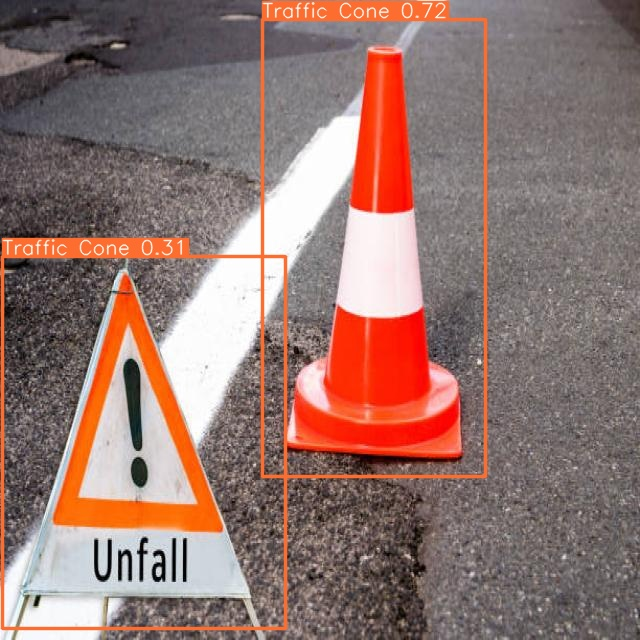


Image: IMG_22831.jpg
Detections: 2
  Bus: 0.68
  Car: 0.35


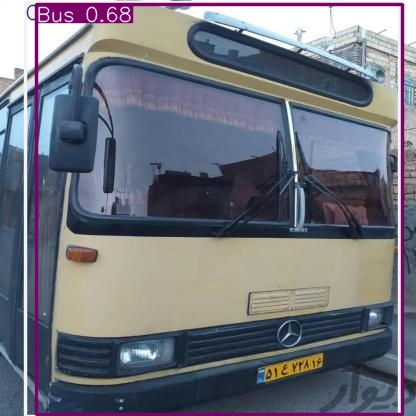


Image: IMG_22779.jpg
Detections: 1
  Manhole: 0.78


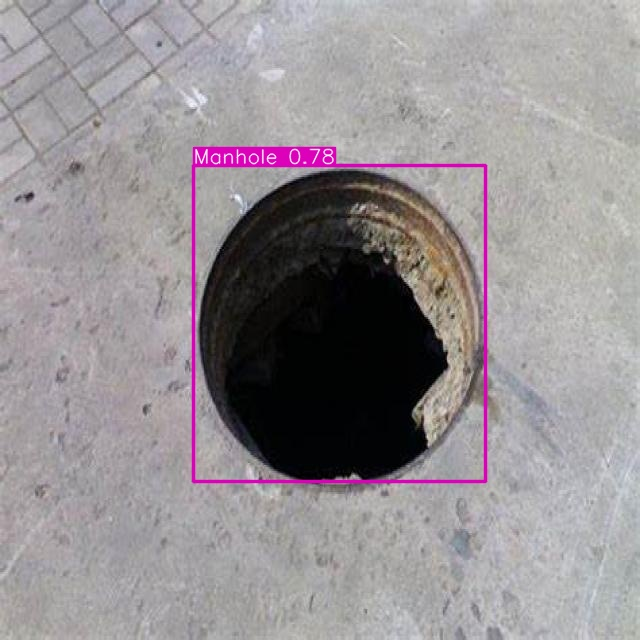


Image: IMG_22407.jpg
Detections: 2
  Stairs: 0.53
  Stairs: 0.26


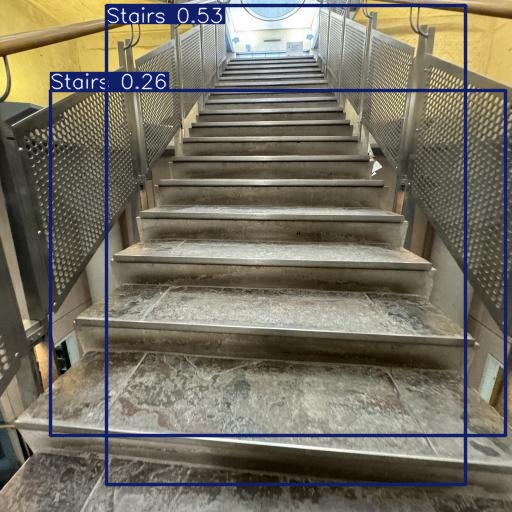


Image: IMG_22001.jpg
Detections: 1
  Person: 0.53


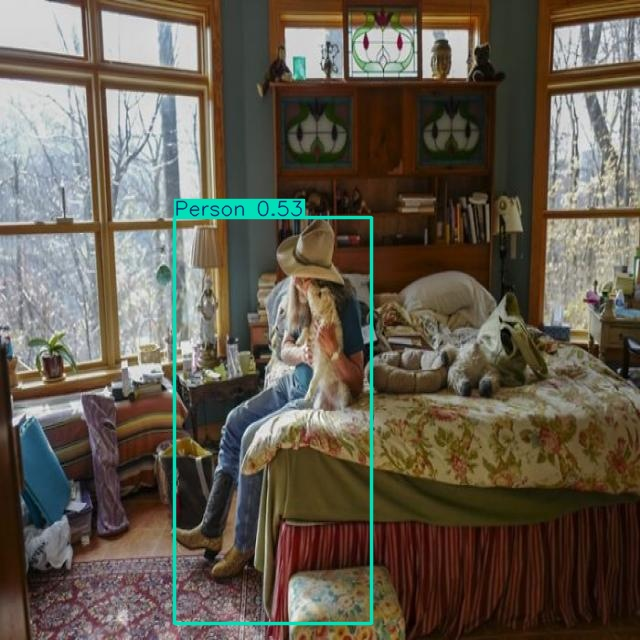

In [9]:

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display, Image
import random

MODEL_PATH = (
    "/kaggle/working/vision_assist/"
    "rod_baseline_smoke/weights/best.pt"
)
IMAGE_DIR = Path("/kaggle/working/rod_detection/valid/images")
OUTPUT_DIR = Path("/kaggle/working/vision_assist/sample_predictions")

model = YOLO(MODEL_PATH)

images = [
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

random.seed(42)
samples = random.sample(images, min(5, len(images)))

for image_path in samples:
    result = model.predict(
        source=str(image_path),
        conf=0.25,
        imgsz=640,
        device=0,
        verbose=False,
    )[0]

    print(f"\nImage: {image_path.name}")
    print("Detections:", len(result.boxes))

    for box in result.boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())
        print(f"  {model.names[class_id]}: {confidence:.2f}")

    # Render the annotated image directly in the notebook.
    annotated = result.plot()
    display(Image(data=__import__("cv2").imencode(
        ".jpg", annotated
    )[1].tobytes()))


In [10]:
from IPython.display import FileLink, display

model_path = (
    "/kaggle/working/vision_assist/"
    "rod_baseline_smoke/weights/best.pt"
)

display(FileLink(model_path))

/kaggle/working/vision_assist/rod_baseline_smoke/weights/best.pt

In [16]:

from kaggle_secrets import UserSecretsClient
import requests

token = UserSecretsClient().get_secret("GITHUB_TOKEN")

response = requests.get(
    "https://api.github.com/repos/SudhaMsr/VisionAssist-MVP",
    headers={
        "Authorization": f"Bearer {token}",
        "Accept": "application/vnd.github+json",
    },
    timeout=30,
)

print("Repository access:", response.status_code)

if response.ok:
    permissions = response.headers.get("X-Accepted-GitHub-Permissions")
    print("Required permissions: Contents: write")
    print("GitHub permission header:", permissions or "Not provided")
else:
    print(response.text[:300])


Repository access: 200
Required permissions: Contents: write
GitHub permission header: metadata=read


In [17]:

from pathlib import Path
from kaggle_secrets import UserSecretsClient
import requests
import base64

# Configuration
REPO = "SudhaMsr/VisionAssist-MVP"
DESTINATION = "models/rod_baseline_smoke_best.pt"
MODEL = Path(
    "/kaggle/working/vision_assist/rod_baseline_smoke/weights/best.pt"
)

# Check that the trained model exists
if not MODEL.exists():
    raise FileNotFoundError(
        f"Model not found: {MODEL}\n"
        "Check that your training session and checkpoint still exist."
    )

print(f"Model size: {MODEL.stat().st_size / (1024 * 1024):.2f} MB")

# Retrieve token securely from Kaggle Secrets
token = UserSecretsClient().get_secret("GITHUB_TOKEN")

headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github+json",
    "X-GitHub-Api-Version": "2022-11-28",
}

# Verify repository access
repo_url = f"https://api.github.com/repos/{REPO}"
repo_response = requests.get(repo_url, headers=headers, timeout=30)
repo_response.raise_for_status()

branch = repo_response.json()["default_branch"]
print(f"Repository accessible. Branch: {branch}")

# Prepare GitHub file upload
file_url = (
    f"https://api.github.com/repos/{REPO}/contents/{DESTINATION}"
)

payload = {
    "message": "Add Vision Assist YOLO baseline checkpoint",
    "branch": branch,
    "content": base64.b64encode(MODEL.read_bytes()).decode("ascii"),
}

# If the file already exists, update it rather than creating a duplicate
existing = requests.get(
    file_url,
    headers=headers,
    params={"ref": branch},
    timeout=30,
)

if existing.status_code == 200:
    payload["sha"] = existing.json()["sha"]
    payload["message"] = "Update Vision Assist YOLO baseline checkpoint"
elif existing.status_code != 404:
    existing.raise_for_status()

# Upload checkpoint
response = requests.put(
    file_url,
    headers=headers,
    json=payload,
    timeout=120,
)

if response.status_code not in (200, 201):
    raise RuntimeError(
        f"Upload failed: HTTP {response.status_code}\n"
        f"GitHub response: {response.text}"
    )

result = response.json()

print("\nUPLOAD SUCCESSFUL!")
print("Commit:", result["commit"]["html_url"])
print("Model file:", result["content"]["html_url"])
print("Size:", f"{MODEL.stat().st_size / (1024 * 1024):.2f} MB")


Model size: 6.21 MB
Repository accessible. Branch: main

UPLOAD SUCCESSFUL!
Commit: https://github.com/SudhaMsr/VisionAssist-MVP/commit/db2612cc4d722c411b9b59d23d091b669deb49df
Model file: https://github.com/SudhaMsr/VisionAssist-MVP/blob/main/models/rod_baseline_smoke_best.pt
Size: 6.21 MB


In [18]:

from pathlib import Path

roots = [
    Path("/kaggle/working"),
    Path("/kaggle/input"),
]

for root in roots:
    print(f"\n--- {root} ---")
    if not root.exists():
        print("Not found")
        continue

    shown = 0
    for path in root.rglob("*"):
        if path.is_file():
            # Avoid listing huge datasets and cache directories in detail
            if any(part in {
                ".git", "__pycache__", ".cache",
                "node_modules"
            } for part in path.parts):
                continue

            print(path)
            shown += 1
            if shown >= 60:
                print("...listing capped at 60 files")
                break



--- /kaggle/working ---
/kaggle/working/rod_detection.yaml
/kaggle/working/yolov8n.pt
/kaggle/working/weights/yolo26n.pt
/kaggle/working/.virtual_documents/__notebook_source__.ipynb
/kaggle/working/rod_detection/train/labels.cache
/kaggle/working/rod_detection/valid/labels.cache
/kaggle/working/rod_detection/test/labels/IMG_19236.txt
/kaggle/working/rod_detection/test/labels/IMG_19298.txt
/kaggle/working/rod_detection/test/labels/IMG_19674.txt
/kaggle/working/rod_detection/test/labels/IMG_20530.txt
/kaggle/working/rod_detection/test/labels/IMG_19392.txt
/kaggle/working/rod_detection/test/labels/IMG_20607.txt
/kaggle/working/rod_detection/test/labels/IMG_19329.txt
/kaggle/working/rod_detection/test/labels/IMG_20584.txt
/kaggle/working/rod_detection/test/labels/IMG_20777.txt
/kaggle/working/rod_detection/test/labels/IMG_20491.txt
/kaggle/working/rod_detection/test/labels/IMG_20182.txt
/kaggle/working/rod_detection/test/labels/IMG_19635.txt
/kaggle/working/rod_detection/test/labels/IMG_2

In [19]:

from pathlib import Path
from kaggle_secrets import UserSecretsClient
import requests
import base64

REPO = "SudhaMsr/VisionAssist-MVP"

files_to_upload = {
    ".virtual_documents/__notebook_source__.ipynb":
        Path("/kaggle/working/.virtual_documents/__notebook_source__.ipynb"),
    "configs/rod_detection.yaml":
        Path("/kaggle/working/rod_detection.yaml"),
}

readme = """# Vision Assist MVP

Experimental assistive-vision prototype using YOLO object detection.

## Current baseline
- Dataset: ROD obstacle detection dataset
- Model: YOLOv8n pretrained baseline
- Preliminary one-epoch validation mAP50: 0.6746
- Preliminary one-epoch validation mAP50-95: 0.4664

These are preliminary validation results, not final test-set results.
This prototype is experimental and is not safety-grade navigation software.

## Contents
- `notebooks/`: training notebook
- `configs/`: dataset configuration
- `models/`: saved model checkpoints

## Dataset
The dataset is obtained separately from Kaggle. Dataset images and labels
are not included in this repository.

## Reproducibility
Review the notebook for preprocessing, training and validation steps.
Check dataset paths and dependencies before rerunning.
"""

files_to_upload["README.md"] = None

token = UserSecretsClient().get_secret("GITHUB_TOKEN")
headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github+json",
    "X-GitHub-Api-Version": "2022-11-28",
}

repo_response = requests.get(
    f"https://api.github.com/repos/{REPO}",
    headers=headers,
    timeout=30,
)
repo_response.raise_for_status()
branch = repo_response.json()["default_branch"]

# Move the notebook into a clear repository folder
uploads = {}

notebook = files_to_upload[
    ".virtual_documents/__notebook_source__.ipynb"
]
if notebook.exists():
    uploads["notebooks/vision_assist_v1.ipynb"] = notebook.read_bytes()
else:
    print("Notebook source file not found; notebook upload skipped.")

config = files_to_upload["configs/rod_detection.yaml"]
if config.exists():
    uploads["configs/rod_detection.yaml"] = config.read_bytes()
else:
    print("Dataset YAML not found; config upload skipped.")

uploads["README.md"] = readme.encode("utf-8")

for path, content in uploads.items():
    url = f"https://api.github.com/repos/{REPO}/contents/{path}"

    existing = requests.get(
        url, headers=headers, params={"ref": branch}, timeout=30
    )

    payload = {
        "message": f"Add or update {path}",
        "branch": branch,
        "content": base64.b64encode(content).decode("ascii"),
    }

    if existing.status_code == 200:
        payload["sha"] = existing.json()["sha"]
    elif existing.status_code != 404:
        existing.raise_for_status()

    result = requests.put(
        url, headers=headers, json=payload, timeout=120
    )

    if result.status_code not in (200, 201):
        print(f"FAILED: {path} — {result.status_code}")
        print(result.text[:500])
        continue

    print(f"UPLOADED: {path}")
    print(result.json()["content"]["html_url"])

print("\nFinished. Check the repository for uploaded files.")


UPLOADED: notebooks/vision_assist_v1.ipynb
https://github.com/SudhaMsr/VisionAssist-MVP/blob/main/notebooks/vision_assist_v1.ipynb
UPLOADED: configs/rod_detection.yaml
https://github.com/SudhaMsr/VisionAssist-MVP/blob/main/configs/rod_detection.yaml
UPLOADED: README.md
https://github.com/SudhaMsr/VisionAssist-MVP/blob/main/README.md

Finished. Check the repository for uploaded files.
